In [2]:
import tensorflow as tf
from tensorflow.keras import datasets, layers, models
from tensorflow.keras.optimizers import Adam
import keras
from keras.models import Sequential, Model
from keras.layers import *
from keras.utils import Sequence
from keras.layers import Conv2D, MaxPooling2D, Conv2DTranspose
from qkeras import *

from keras.utils import Sequence
from keras.callbacks import CSVLogger
from keras.callbacks import EarlyStopping
from keras.losses import MeanSquaredError

import os
import random
from datetime import datetime
import time

import matplotlib.pyplot as plt

pi = 3.14159265359

maxval=1e9
minval=1e-9

2025-11-18 16:08:04.948800: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  SSE4.1 SSE4.2 AVX AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [4]:
import importlib
import DAE_DataGenerator

importlib.reload(DAE_DataGenerator)
from DAE_DataGenerator import OptimizedDataGenerator as DAE_optDG
#from dataprep import *
from OptimizedDataGenerator_v2 import OptimizedDataGenerator
from loss import *
from dataset_utils import add_noise



In [5]:
'''Load weights and extract the encoder'''

import models
importlib.reload(models)
from models import CreateAutoEncoder

weights_path = './trained_models/DAE/model-84987d3f-DAE_2bit_80eN_Decoder64_ConvT-checkpoints'
base_dir = weights_path
checkpoint_files = [os.path.join(base_dir, f) for f in os.listdir(base_dir) if f.endswith('.hdf5')]
latest_checkpoint = max(checkpoint_files, key=os.path.getmtime)
#training_cp_path = os.path.join(base_dir, 'training_log.csv')
#training_history = pd.read_csv(training_cp_path)

print(f"Loading model from {latest_checkpoint}")
DAE=CreateAutoEncoder((16,16,2), n_filters=5, pool_size=2, conv_kernel_size = 3, decoder_filters = 64)
DAE.load_weights(latest_checkpoint)
model_summary = [[layer.name, layer.output.shape] for layer in DAE.layers]

for i, layer in enumerate(DAE.layers):
    print('index:', i, layer.name)


layer_name = DAE.layers[8].name 
# print(layer_name)
encoder = Model(inputs=DAE.input, outputs=DAE.get_layer(layer_name).output)
encoder.trainable = False
encoder.summary()

# encoder = DAE.get_layer(layer_name)

print(encoder.output.shape)




Loading model from ./trained_models/DAE/model-84987d3f-DAE_2bit_80eN_Decoder64_ConvT-checkpoints/weights.790-t0.0158-v0.0158.hdf5


2025-11-18 16:09:46.589771: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:980] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2025-11-18 16:09:46.648088: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:980] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2025-11-18 16:09:46.648435: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:980] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2025-11-18 16:09:46.649444: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  SSE4.1 SSE4.2 AVX AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropri

index: 0 input_1
index: 1 q_separable_conv2d
index: 2 q_activation
index: 3 average_pooling2d
index: 4 q_activation_1
index: 5 q_conv2d
index: 6 q_activation_2
index: 7 average_pooling2d_1
index: 8 q_activation_3
index: 9 conv2d_transpose
index: 10 q_activation_4
index: 11 conv2d_transpose_1
index: 12 q_activation_5
index: 13 conv2d
index: 14 q_activation_6
Model: "model_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_1 (InputLayer)        [(None, 16, 16, 2)]       0         
                                                                 
 q_separable_conv2d (QSepara  (None, 16, 16, 5)        33        
 bleConv2D)                                                      
                                                                 
 q_activation (QActivation)  (None, 16, 16, 5)         0         
                                                                 
 average_pooling2d (AverageP 

In [6]:
'''attach a dense regression network to the latent space'''
from models import var_network

x_in = encoder.input
lat_shape = encoder.output.shape
dense = var_network(encoder.output, hidden=16, output=14)
model = Model(inputs=x_in, outputs=dense)

model.summary()

model.compile(
    optimizer=tf.keras.optimizers.Nadam(learning_rate=1e-3),
    loss=custom_loss
)


Model: "model_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_1 (InputLayer)        [(None, 16, 16, 2)]       0         
                                                                 
 q_separable_conv2d (QSepara  (None, 16, 16, 5)        33        
 bleConv2D)                                                      
                                                                 
 q_activation (QActivation)  (None, 16, 16, 5)         0         
                                                                 
 average_pooling2d (AverageP  (None, 8, 8, 5)          0         
 ooling2D)                                                       
                                                                 
 q_activation_1 (QActivation  (None, 8, 8, 5)          0         
 )                                                               
                                                           

In [7]:
dataset_base_dir = "/uscms/home/bweiss/nobackup/smart-pixels/"
tfrecords_base_dir = os.path.join(dataset_base_dir, "tfrecords")

dataset_dir_train = os.path.join(dataset_base_dir, "dataset_3sr_16x16_50x12P5_parquets", 'train/')
dataset_dir_val = os.path.join(dataset_base_dir, "dataset_3sr_16x16_50x12P5_parquets", 'test/')

tfrecords_dir_train = os.path.join(tfrecords_base_dir, "TFR_train", '3sr_16x16_Opt2bit')
tfrecords_dir_val   = os.path.join(tfrecords_base_dir, "TFR_val", '3sr_16x16_Opt2bit')

print(dataset_dir_val)
batch_size = 5000
val_batch_size = 5000
train_file_size = 80
val_file_size = 20

/uscms/home/bweiss/nobackup/smart-pixels/dataset_3sr_16x16_50x12P5_parquets/test/


In [28]:
'''CHANGE THRESHOLDS AND TO_STANDARDIZE!!'''
start_time = time.time()
validation_generator = OptimizedDataGenerator(
    dataset_base_dir = dataset_dir_val,
    file_type = "parquet",
    data_format = "3D",
    batch_size = val_batch_size,
    # optimize_batch_size = True,
    file_count = val_file_size,
    to_standardize= True,
    select_contained = True,
    noise = [0,80], #[mean, sigma]
    min_threshold = None,
    max_threshold = None,
    
    labels_list = ['x-midplane','y-midplane','cotAlpha','cotBeta'],
    input_shape = (2,16,16), # (20,13,21),
    transpose = (0,2,3,1),
    shuffle = False, 
    files_from_end=True,

    tfrecords_dir = tfrecords_dir_val,
    use_time_stamps = [0,19],
    max_workers = 2
)
print("--- Validation generator %s seconds ---" % (time.time() - start_time))

# training generator
start_time = time.time()
training_generator = OptimizedDataGenerator(
    dataset_base_dir = dataset_dir_train,
    file_type = "parquet",
    data_format = "3D",
    batch_size = batch_size,
    # optimize_batch_size = True,
    file_count = train_file_size,
    to_standardize= True,
    select_contained = True,
    labels_list = ['x-midplane','y-midplane','cotAlpha','cotBeta'],
    input_shape = (2,16,16), # (20,13,21),
    transpose = (0,2,3,1),
    shuffle = False, # True 
    noise = [0,80],
    # threshold = -1,
    tfrecords_dir = tfrecords_dir_train,
    use_time_stamps = [0,19],
    max_workers = 2
)

print("--- Training generator %s seconds ---" % (time.time() - start_time))

Processing Files...: 100%|██████████| 20/20 [00:07<00:00,  2.62it/s]


Directory /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_val/3sr_16x16_80eNoise is removed...


Saving batches as TFRecords: 100%|██████████| 21/21 [00:17<00:00,  1.22it/s]


Metadata saved successfully ast /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_val/3sr_16x16_80eNoise/metadata.json
Loading metadata from /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_val/3sr_16x16_80eNoise/metadata.json


--- Validation generator 26.268668174743652 seconds ---


Processing Files...: 100%|██████████| 80/80 [00:30<00:00,  2.64it/s]


Directory /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_train/3sr_16x16_80eNoise is removed...


Saving batches as TFRecords: 100%|██████████| 84/84 [01:08<00:00,  1.22it/s]


Metadata saved successfully ast /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_train/3sr_16x16_80eNoise/metadata.json
Loading metadata from /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_train/3sr_16x16_80eNoise/metadata.json


--- Training generator 101.73654198646545 seconds ---


In [8]:
# Loading pre-generated TFRecords
validation_generator = OptimizedDataGenerator(
    load_from_tfrecords_dir= tfrecords_dir_val,
    shuffle=False,
    seed=42,
    quantize=False,
)

training_generator = OptimizedDataGenerator(
    load_from_tfrecords_dir = tfrecords_dir_train,
    shuffle=False,
    seed=42,
    quantize=False,
)

Loading metadata from /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_val/3sr_16x16_Opt2bit/metadata.json


Loading metadata from /uscms/home/bweiss/nobackup/smart-pixels/tfrecords/TFR_train/3sr_16x16_Opt2bit/metadata.json


tf.Tensor([-0.24053733  0.00675513 -0.8032356  -0.74184495], shape=(4,), dtype=float32)
max: 0.9931157
min: -0.9948069


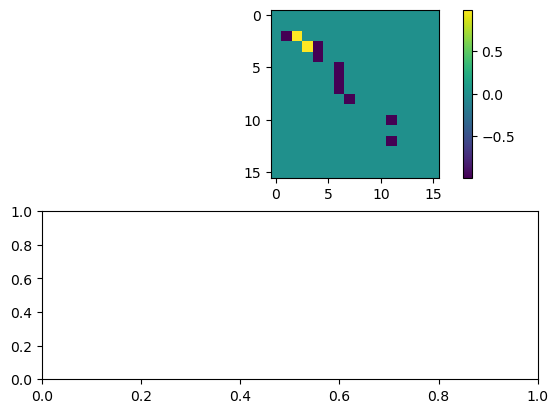

In [9]:
import matplotlib.pyplot as plt
from matplotlib import colors

n=90

cluster = training_generator[0]
# print(np.max(cluster[0].numpy()))
print(cluster[1][n])
cluster=cluster[0][:,:,:,0]

print('max:', np.max(cluster.numpy()))
print('min:', np.min(cluster.numpy()))

fig,ax = plt.subplots(2,1)
h = ax[0].imshow(cluster[n])
fig.colorbar(h)

In [10]:
from datetime import datetime
tname = 'DAE_regression_opt2bit'
fingerprint = '%08x' % random.randrange(16**8)
timestamp = datetime.now().strftime('%Y%m%d-%H%M%S')
os.makedirs("trained_models", exist_ok=True)
base_dir = f'./trained_models/DAE_regression/model-{fingerprint}-{tname}-checkpoints'
os.makedirs(base_dir, exist_ok=True)  
checkpoint_filepath = base_dir + '/weights.{epoch:02d}-t{loss:.2f}-v{val_loss:.2f}.hdf5'
print(fingerprint)

8d931875


In [11]:
from tensorflow.keras.callbacks import CSVLogger, EarlyStopping, ModelCheckpoint, Callback

early_stopping_patience = 100

class CustomModelCheckpoint(ModelCheckpoint):
    def on_epoch_end(self, epoch, logs=None):
        super().on_epoch_end(epoch, logs)
        checkpoints = [f for f in os.listdir(base_dir) if f.startswith('weights')]
        if len(checkpoints) > 1:
            checkpoints.sort(key=lambda x: os.path.getmtime(os.path.join(base_dir,x)))
            for checkpoint in checkpoints[:-1]:
                os.remove(os.path.join(base_dir, checkpoint))

es = EarlyStopping(patience=early_stopping_patience, restore_best_weights=True)

mcp = CustomModelCheckpoint(
    filepath=checkpoint_filepath,
    save_weights_only=True,
    monitor='val_loss',
    save_best_only=True,
    save_freq='epoch',
    verbose=1
)

csv_logger = CSVLogger(f'{base_dir}/training_log.csv', append=True)

In [12]:
history = model.fit(
        x=training_generator,
        validation_data=validation_generator,
        callbacks=[es, mcp, csv_logger],
        epochs=800,
        shuffle=False,
        verbose=1
    )

Epoch 1/800


2025-11-18 16:11:01.313044: I tensorflow/stream_executor/cuda/cuda_blas.cc:1614] TensorFloat-32 will be used for the matrix multiplication. This will only be logged once.
2025-11-18 16:11:01.350882: I tensorflow/stream_executor/cuda/cuda_dnn.cc:384] Loaded cuDNN version 8800


 3/84 [>.............................] - ETA: 3s - loss: 103600.1797  

2025-11-18 16:11:01.604887: I tensorflow/core/util/cuda_solvers.cc:179] Creating GpuSolver handles for stream 0x556c837d8270


83/84 [============================>.] - ETA: 0s - loss: 47086.9219
Epoch 1: val_loss improved from inf to 20324.59375, saving model to ./trained_models/DAE_regression/model-8d931875-DAE_regression_opt2bit-checkpoints/weights.01-t46767.40-v20324.59.hdf5
84/84 [==============================] - 10s 96ms/step - loss: 46767.4023 - val_loss: 20324.5938
Epoch 2/800
84/84 [==============================] - ETA: 0s - loss: 15990.1729
Epoch 2: val_loss improved from 20324.59375 to 12175.37793, saving model to ./trained_models/DAE_regression/model-8d931875-DAE_regression_opt2bit-checkpoints/weights.02-t15990.17-v12175.38.hdf5
84/84 [==============================] - 7s 88ms/step - loss: 15990.1729 - val_loss: 12175.3779
Epoch 3/800
84/84 [==============================] - ETA: 0s - loss: 9471.3662
Epoch 3: val_loss improved from 12175.37793 to 7213.01660, saving model to ./trained_models/DAE_regression/model-8d931875-DAE_regression_opt2bit-checkpoints/weights.03-t9471.37-v7213.02.hdf5
84/84 [==

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)



84/84 [==============================] - ETA: 0s - loss: -7386.9756
Epoch 568: val_loss did not improve from -7602.96875
84/84 [==============================] - 7s 86ms/step - loss: -7386.9756 - val_loss: -7157.7793
Epoch 569/800
84/84 [==============================] - ETA: 0s - loss: -7335.9707
Epoch 569: val_loss did not improve from -7602.96875
84/84 [==============================] - 7s 84ms/step - loss: -7335.9707 - val_loss: -7371.6924
Epoch 570/800
84/84 [==============================] - ETA: 0s - loss: -7364.2051
Epoch 570: val_loss did not improve from -7602.96875
84/84 [==============================] - 9s 108ms/step - loss: -7364.2051 - val_loss: -7418.4170
Epoch 571/800
84/84 [==============================] - ETA: 0s - loss: -7375.0854
Epoch 571: val_loss did not improve from -7602.96875
84/84 [==============================] - 8s 95ms/step - loss: -7375.0854 - val_loss: -7578.9565
Epoch 572/800
84/84 [==============================] - ETA: 0s - loss: -7437.6035
Epoch 5